# Baseline Model — Prediksi Ketidakpatuhan Pengobatan Pasien CIMAS

Notebook ini digunakan untuk **identifikasi awal** performa model machine learning pada dataset CIMAS.

## Skenario
Skenario yang dijalankan adalah **Baseline**, yaitu:

- Tanpa SMOTE.
- Tanpa Random Undersampling.
- Tanpa Class Weight.
- Tanpa `sample_weight`.
- Tanpa `class_weights`.

## Target Klasifikasi
- `NON-ADHERENT = 1` sebagai kelas positif.
- `ADHERENT = 0` sebagai kelas negatif.

Catatan perbaikan:
- Missing value distandarkan menjadi `np.nan`, bukan `pd.NA`, agar tidak menyebabkan error `boolean value of NA is ambiguous`.
- Kolom kategorikal dibuat bertipe `object` agar kompatibel dengan `SimpleImputer` dan `OneHotEncoder`.


## 1. Import Library

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42


## 2. Load Dataset

Ubah `DATA_PATH` sesuai lokasi dataset CIMAS. File dapat berupa `.csv`, `.xlsx`, atau `.xls`.


In [2]:
DATA_PATH = "dataset/Cimas NCD Patient and  Medical Claims Data Medication Adherence Final.csv"  # ubah sesuai file dataset

def load_dataset(path):
    path = str(path)
    if path.endswith(".xlsx") or path.endswith(".xls"):
        return pd.read_excel(path)
    return pd.read_csv(path)

df = load_dataset(DATA_PATH)

print("Ukuran dataset awal:", df.shape)
display(df.head())


Ukuran dataset awal: (8142, 16)


,BENEFICIARY,YEAR,Diagnosis,AGE,AGEGROUP,SCHEMETYPE,HOSPITALCOVERTYPE,ANNUALCONTRIBUTION,WELLNESSPROGRAM,GENDER,ANNUALCLAIMAMOUNT,FINALTHRESHOLD,COMPLICATIONDVELOPMENT,COMORBIDITY,COMORBIDITY.1,UNITS
0,3260976114,2022,Diabetes,16,16-20,MEDIUMLEVEL,PRIVATE_GRADEA,900,SUBSCRIBED,MALE,219.65,ADHERENT,YES,NO,NO,69
1,3958374122,2022,Diabetes,16,16-20,MEDIUMLEVEL,PRIVATE_GRADEA,900,SUBSCRIBED,FEMALE,928.35,ADHERENT,YES,NO,NO,397
2,3130974113,2022,Diabetes,17,16-20,MEDIUMLEVEL,PRIVATE_GRADEA,900,SUBSCRIBED,FEMALE,581.64,NON-ADHERENT,YES,NO,NO,418
3,3278475122,2022,Diabetes,17,16-20,MEDIUMLEVEL,PRIVATE_GRADEA,900,SUBSCRIBED,FEMALE,328.61,NON-ADHERENT,NO,NO,NO,21
4,3395816142,2022,Diabetes,17,16-20,MEDIUMLEVEL,BASIC_TO_GRADEB,768,NOT_SUBSCRIBED,FEMALE,210.93,NON-ADHERENT,YES,YES,YES,42


## 3. Pembersihan Data dan Standarisasi Format

Tahap ini merapikan struktur data dan menyamakan format nilai. Missing value diubah menjadi `np.nan` agar kompatibel dengan pipeline scikit-learn.


In [3]:
df = df.copy()

# Rapikan nama kolom
df.columns = df.columns.str.strip()

# Hapus baris header ganda jika ada
if "FINALTHRESHOLD" in df.columns:
    df = df[df["FINALTHRESHOLD"].astype(str).str.strip().str.upper() != "FINALTHRESHOLD"]

if "BENEFICIARY" in df.columns:
    df = df[df["BENEFICIARY"].astype(str).str.strip().str.upper() != "BENEFICIARY"]

# Rename kolom yang kurang konsisten
rename_map = {
    "COMPLICATIONDVELOPMENT": "COMPLICATIONDEVELOPMENT",
    "COMORBIDITY.1": "COMORBIDITY_SECONDARY"
}
df = df.rename(columns=rename_map)

# Rapikan nilai string tanpa menggunakan pd.NA sebagai missing value akhir
object_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

for col in object_cols:
    df[col] = df[col].astype("object")
    df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)
    df[col] = df[col].replace({
        "": np.nan,
        "nan": np.nan,
        "NaN": np.nan,
        "None": np.nan,
        "NULL": np.nan,
        "null": np.nan,
        "<NA>": np.nan
    })

# Standarisasi nilai Diagnosis jika ada typo
if "Diagnosis" in df.columns:
    df["Diagnosis"] = df["Diagnosis"].replace({
        "Hypetension": "Hypertension",
        "HYPETENSION": "Hypertension",
        "hypertension": "Hypertension",
        "DIABETES": "Diabetes",
        "diabetes": "Diabetes"
    })

TARGET_COL = "FINALTHRESHOLD"
GROUP_COL = "BENEFICIARY"

if TARGET_COL not in df.columns:
    raise ValueError(f"Kolom target '{TARGET_COL}' tidak ditemukan.")

if GROUP_COL not in df.columns:
    raise ValueError(f"Kolom group '{GROUP_COL}' tidak ditemukan.")

# Standarisasi target
df[TARGET_COL] = (
    df[TARGET_COL]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace("_", "-", regex=False)
    .str.replace(" ", "-", regex=False)
)

# Ambil hanya target valid
df = df[df[TARGET_COL].isin(["ADHERENT", "NON-ADHERENT"])].copy()

# Pastikan tidak ada pd.NA tersisa
df = df.replace({pd.NA: np.nan})

print("Ukuran dataset setelah cleaning:", df.shape)
display(df[TARGET_COL].value_counts().rename("jumlah").to_frame())


Ukuran dataset setelah cleaning: (8141, 16)


,jumlah
FINALTHRESHOLD,
NON-ADHERENT,6600
ADHERENT,1541


## 4. Definisi Target

Pada penelitian ini, kelas positif adalah pasien tidak patuh.

- `NON-ADHERENT = 1`
- `ADHERENT = 0`


In [4]:
df["target"] = df[TARGET_COL].map({
    "ADHERENT": 0,
    "NON-ADHERENT": 1
}).astype(int)

target_distribution = (
    df["target"]
    .map({0: "ADHERENT", 1: "NON-ADHERENT"})
    .value_counts()
)

display(pd.DataFrame({
    "jumlah": target_distribution,
    "persentase (%)": (target_distribution / target_distribution.sum() * 100).round(2)
}))


,jumlah,persentase (%)
target,,
NON-ADHERENT,6600,81.07
ADHERENT,1541,18.93


## 5. Visualisasi Distribusi Kelas

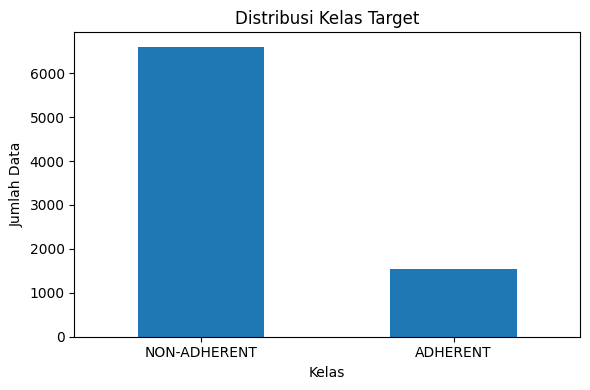

,jumlah,persentase (%)
target,,
NON-ADHERENT,6600,81.07
ADHERENT,1541,18.93


In [5]:
class_counts = (
    df["target"]
    .map({0: "ADHERENT", 1: "NON-ADHERENT"})
    .value_counts()
)

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Distribusi Kelas Target")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

class_percent = (class_counts / class_counts.sum() * 100).round(2)
display(
    pd.DataFrame({
        "jumlah": class_counts,
        "persentase (%)": class_percent
    })
)


## 6. Pemilihan Fitur dan Pembagian Data Berbasis BENEFICIARY

`BENEFICIARY` digunakan untuk pembagian data berbasis pasien, tetapi tidak digunakan sebagai fitur prediktif.


In [6]:
drop_cols = [TARGET_COL, "target"]

groups = df[GROUP_COL].astype(str)
drop_cols.append(GROUP_COL)

# YEAR dihapus jika hanya memiliki satu nilai unik
if "YEAR" in df.columns and df["YEAR"].nunique(dropna=True) <= 1:
    drop_cols.append("YEAR")

X = df.drop(columns=drop_cols, errors="ignore").copy()
y = df["target"].astype(int)

# Pastikan missing value kompatibel dengan scikit-learn
X = X.replace({pd.NA: np.nan})

# Konversi kolom numerik
numeric_candidates = ["AGE", "ANNUALCONTRIBUTION", "ANNUALCLAIMAMOUNT", "UNITS"]
for col in numeric_candidates:
    if col in X.columns:
        X[col] = pd.to_numeric(X[col], errors="coerce")

# Pastikan kolom non-numerik bertipe object, bukan StringDtype pandas
for col in X.columns:
    if col not in numeric_candidates:
        X[col] = X[col].astype("object")

# Split 80:20 menggunakan StratifiedGroupKFold
# n_splits=5 menghasilkan 1 fold sebagai test sekitar 20%
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

# Bersihkan lagi pd.NA jika ada sisa setelah split
X_train = X_train.replace({pd.NA: np.nan})
X_test = X_test.replace({pd.NA: np.nan})

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)

print("\nDistribusi kelas data latih:")
display(
    y_train.map({0: "ADHERENT", 1: "NON-ADHERENT"})
    .value_counts()
    .to_frame("jumlah")
)

print("\nDistribusi kelas data uji:")
display(
    y_test.map({0: "ADHERENT", 1: "NON-ADHERENT"})
    .value_counts()
    .to_frame("jumlah")
)


Ukuran X_train: (6512, 13)
Ukuran X_test : (1629, 13)

Distribusi kelas data latih:


,jumlah
target,
NON-ADHERENT,5280
ADHERENT,1232



Distribusi kelas data uji:


,jumlah
target,
NON-ADHERENT,1320
ADHERENT,309


## 7. Pipeline Pra-Pemrosesan

Pipeline dipelajari dari data latih. Pada data latih pipeline melakukan `fit_transform`, sedangkan pada data uji pipeline hanya melakukan `transform`.


In [7]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)

# OneHotEncoder compatibility untuk versi sklearn berbeda
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", missing_values=np.nan)),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="UNKNOWN", missing_values=np.nan)),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)


Fitur numerik: ['AGE', 'ANNUALCONTRIBUTION', 'ANNUALCLAIMAMOUNT', 'UNITS']
Fitur kategorikal: ['Diagnosis', 'AGEGROUP', 'SCHEMETYPE', 'HOSPITALCOVERTYPE', 'WELLNESSPROGRAM', 'GENDER', 'COMPLICATIONDEVELOPMENT', 'COMORBIDITY', 'COMORBIDITY_SECONDARY']


## 8. Model Baseline

Semua model pada baseline:
- `class_weight=None`
- tanpa `sample_weight`
- tanpa `class_weights`
- tanpa SMOTE
- tanpa Random Undersampling


In [8]:
models = {
    "Logistic Regression": LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="lbfgs",
        max_iter=1000,
        class_weight=None,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight=None,
        random_state=RANDOM_STATE
    ),
    "SVM": SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        probability=True,
        class_weight=None,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight=None,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# XGBoost baseline: tidak menggunakan sample_weight
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        eval_metric="logloss",
        random_state=RANDOM_STATE
    )
except Exception as e:
    print("XGBoost tidak tersedia:", e)

# LightGBM baseline: class_weight=None
try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        class_weight=None,
        random_state=RANDOM_STATE,
        verbose=-1
    )
except Exception as e:
    print("LightGBM tidak tersedia:", e)

# CatBoost baseline: tidak menggunakan class_weights
try:
    from catboost import CatBoostClassifier
    models["CatBoost"] = CatBoostClassifier(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        random_state=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False
    )
except Exception as e:
    print("CatBoost tidak tersedia:", e)

print("Model baseline yang akan dijalankan:")
print(list(models.keys()))


Model baseline yang akan dijalankan:
['Logistic Regression', 'Decision Tree', 'SVM', 'Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']


## 9. Fungsi Evaluasi

Urutan confusion matrix:
- `NON-ADHERENT` sebagai kelas positif.
- `ADHERENT` sebagai kelas negatif.


In [9]:
def evaluate_model(model_name, pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)

    try:
        y_score = pipeline.predict_proba(X_test)[:, 1]
    except Exception:
        y_score = None

    # Urutan label: 1 = NON-ADHERENT, 0 = ADHERENT
    cm = confusion_matrix(y_test, y_pred, labels=[1, 0])

    TP = cm[0, 0]
    FN = cm[0, 1]
    FP = cm[1, 0]
    TN = cm[1, 1]

    specificity = TN / (TN + FP) if (TN + FP) > 0 else np.nan

    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "recall_sensitivity": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "specificity": specificity,
        "f1_score": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_score) if y_score is not None else np.nan,
        "pr_auc": average_precision_score(y_test, y_score) if y_score is not None else np.nan,
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN
    }

    return metrics, cm, y_pred, y_score


## 10. Training dan Evaluasi Baseline

Hasil hanya ditampilkan di notebook dan tidak disimpan sebagai file output.


In [10]:
baseline_results = []
confusion_matrices = {}
trained_pipelines = {}
predictions = {}
prediction_scores = {}

for model_name, model in models.items():
    print(f"Menjalankan baseline model: {model_name}")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    metrics, cm, y_pred, y_score = evaluate_model(model_name, pipeline, X_test, y_test)

    baseline_results.append(metrics)
    confusion_matrices[model_name] = cm
    trained_pipelines[model_name] = pipeline
    predictions[model_name] = y_pred
    prediction_scores[model_name] = y_score

metrics_df = pd.DataFrame(baseline_results)

metric_order = [
    "model",
    "accuracy",
    "precision",
    "recall_sensitivity",
    "specificity",
    "f1_score",
    "balanced_accuracy",
    "roc_auc",
    "pr_auc",
    "TP",
    "TN",
    "FP",
    "FN"
]

display(
    metrics_df[metric_order]
    .sort_values(by="balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)


Menjalankan baseline model: Logistic Regression
Menjalankan baseline model: Decision Tree
Menjalankan baseline model: SVM
Menjalankan baseline model: Random Forest
Menjalankan baseline model: XGBoost
Menjalankan baseline model: LightGBM
Menjalankan baseline model: CatBoost


,model,accuracy,precision,recall_sensitivity,specificity,f1_score,balanced_accuracy,roc_auc,pr_auc,TP,TN,FP,FN
0,LightGBM,0.875998,0.916542,0.931818,0.637540,0.924117,0.784679,0.927908,0.983501,1230,197,112,90
1,CatBoost,0.869859,0.913433,0.927273,0.624595,0.920301,0.775934,0.927376,0.983007,1224,193,116,96
2,XGBoost,0.872928,0.911917,0.933333,0.614887,0.922501,0.774110,0.931247,0.984175,1232,190,119,88
3,Random Forest,0.853898,0.900741,0.921212,0.566343,0.910861,0.743778,0.915761,0.978802,1216,175,134,104
4,Decision Tree,0.831799,0.895015,0.897727,0.550162,0.896369,0.723945,0.723945,0.886352,1185,170,139,135
5,SVM,0.849601,0.877723,0.946212,0.436893,0.910682,0.691553,0.900618,0.973042,1249,135,174,71
6,Logistic Regression,0.855740,0.872340,0.962879,0.398058,0.915376,0.680469,0.891274,0.971617,1271,123,186,49


## 11. Confusion Matrix per Model

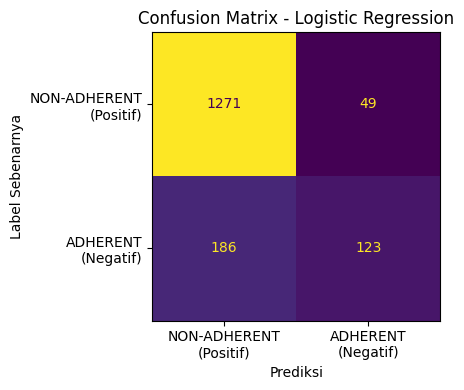

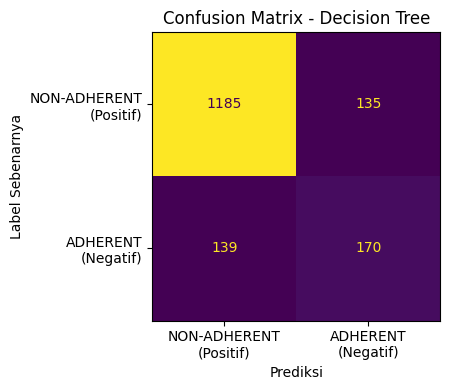

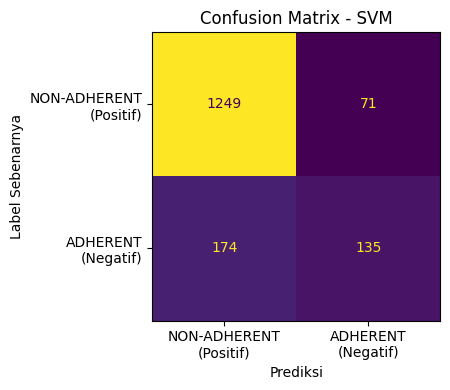

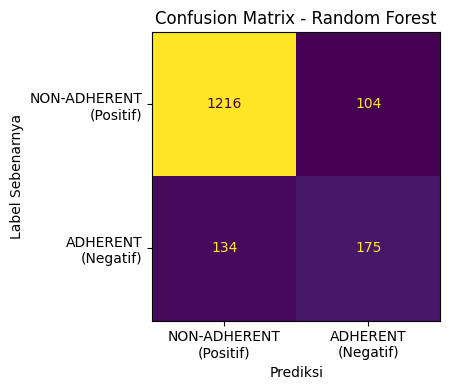

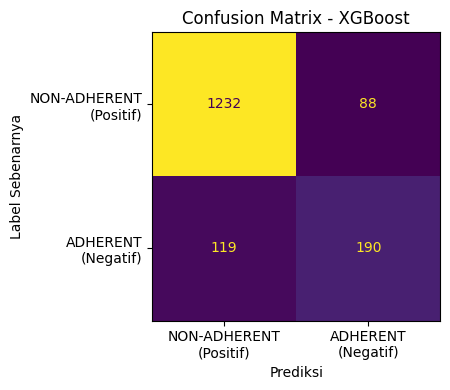

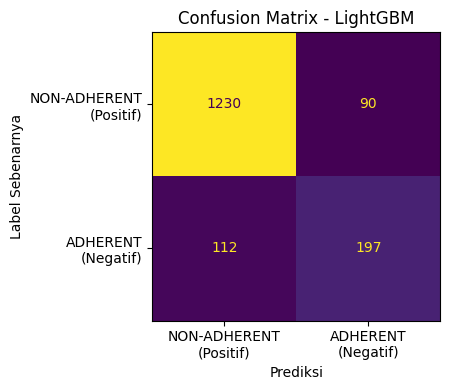

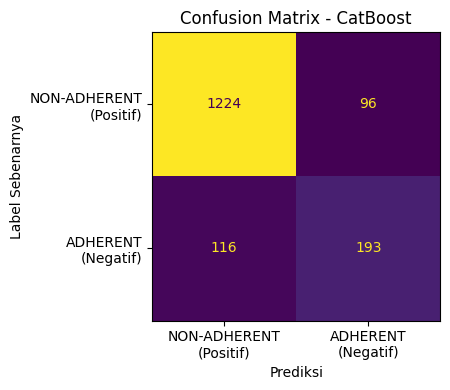

In [11]:
for model_name, cm in confusion_matrices.items():
    fig, ax = plt.subplots(figsize=(5, 4))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "NON-ADHERENT\n(Positif)",
            "ADHERENT\n(Negatif)"
        ]
    )

    disp.plot(ax=ax, values_format="d", colorbar=False)
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Prediksi")
    plt.ylabel("Label Sebenarnya")
    plt.tight_layout()
    plt.show()


## 12. Grafik Perbandingan Semua Metrik Baseline

<Figure size 1400x600 with 0 Axes>

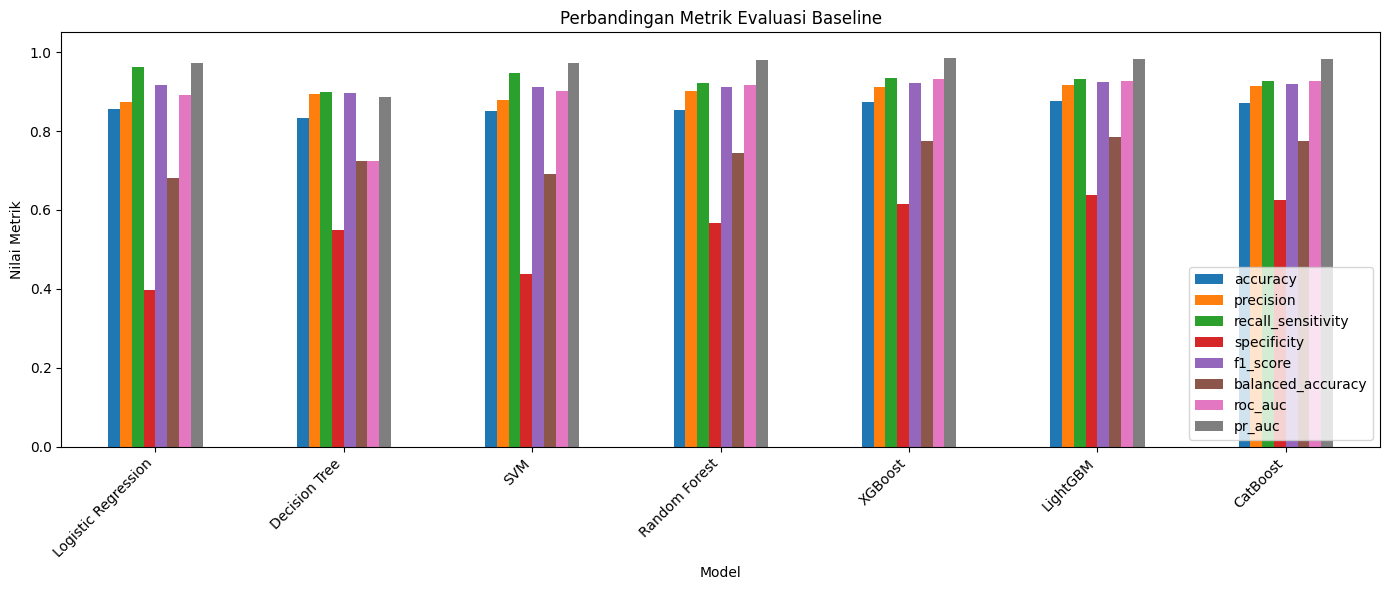

In [12]:
metric_cols = [
    "accuracy",
    "precision",
    "recall_sensitivity",
    "specificity",
    "f1_score",
    "balanced_accuracy",
    "roc_auc",
    "pr_auc"
]

plot_df = metrics_df.set_index("model")[metric_cols]

plt.figure(figsize=(14, 6))
plot_df.plot(kind="bar", figsize=(14, 6))
plt.title("Perbandingan Metrik Evaluasi Baseline")
plt.ylabel("Nilai Metrik")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 13. Grafik Fokus untuk Identifikasi Awal

Metrik yang difokuskan:
- Recall/Sensitivity
- Specificity
- Balanced Accuracy
- PR-AUC


<Figure size 1200x600 with 0 Axes>

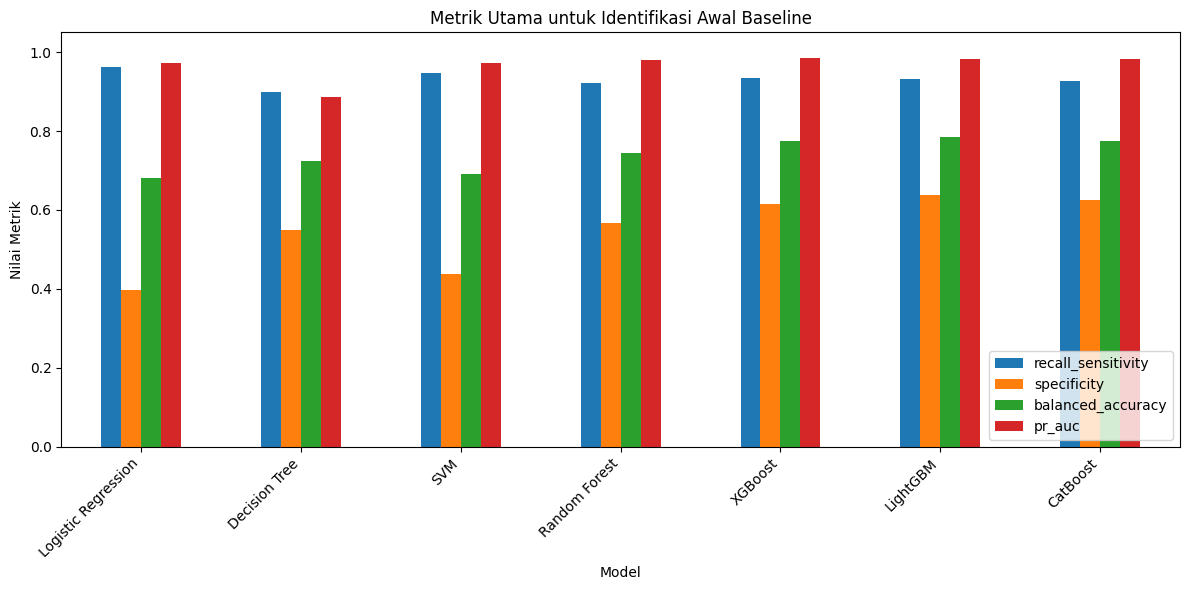

In [13]:
focus_cols = [
    "recall_sensitivity",
    "specificity",
    "balanced_accuracy",
    "pr_auc"
]

focus_df = metrics_df.set_index("model")[focus_cols]

plt.figure(figsize=(12, 6))
focus_df.plot(kind="bar", figsize=(12, 6))
plt.title("Metrik Utama untuk Identifikasi Awal Baseline")
plt.ylabel("Nilai Metrik")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 14. Grafik TP, TN, FP, dan FN

<Figure size 1200x600 with 0 Axes>

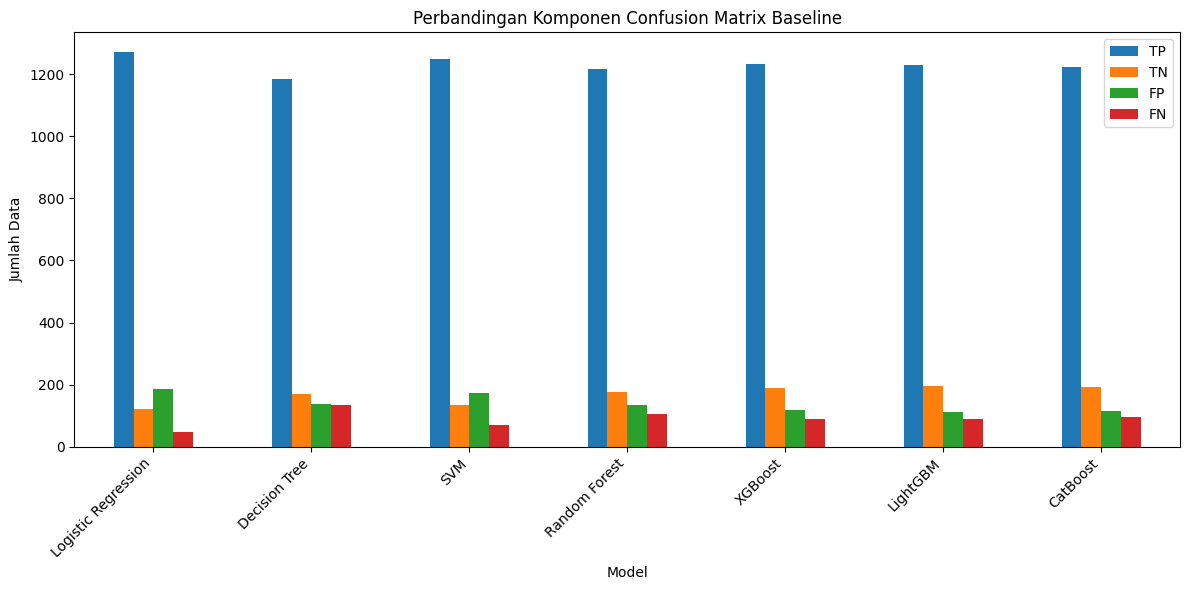

In [14]:
cm_cols = ["TP", "TN", "FP", "FN"]
cm_df = metrics_df.set_index("model")[cm_cols]

plt.figure(figsize=(12, 6))
cm_df.plot(kind="bar", figsize=(12, 6))
plt.title("Perbandingan Komponen Confusion Matrix Baseline")
plt.ylabel("Jumlah Data")
plt.xlabel("Model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 15. Interpretasi Awal Otomatis

In [15]:
best_balanced = metrics_df.sort_values(by="balanced_accuracy", ascending=False).iloc[0]
best_recall = metrics_df.sort_values(by="recall_sensitivity", ascending=False).iloc[0]
best_pr_auc = metrics_df.sort_values(by="pr_auc", ascending=False).iloc[0]

print("Ringkasan Identifikasi Awal Baseline")
print("-" * 60)
print(f"Model terbaik berdasarkan Balanced Accuracy : {best_balanced['model']} ({best_balanced['balanced_accuracy']:.4f})")
print(f"Model terbaik berdasarkan Recall/Sensitivity: {best_recall['model']} ({best_recall['recall_sensitivity']:.4f})")
print(f"Model terbaik berdasarkan PR-AUC             : {best_pr_auc['model']} ({best_pr_auc['pr_auc']:.4f})")

print("\nCatatan interpretasi:")
print("1. Recall tinggi berarti model lebih banyak menangkap pasien NON-ADHERENT.")
print("2. Specificity tinggi berarti model lebih baik mengenali pasien ADHERENT.")
print("3. Balanced accuracy penting karena dataset tidak seimbang.")
print("4. PR-AUC penting untuk melihat keseimbangan precision dan recall pada kelas positif.")
print("5. Jika accuracy tinggi tetapi specificity rendah, model kemungkinan terlalu condong ke kelas NON-ADHERENT.")


Ringkasan Identifikasi Awal Baseline
------------------------------------------------------------
Model terbaik berdasarkan Balanced Accuracy : LightGBM (0.7847)
Model terbaik berdasarkan Recall/Sensitivity: Logistic Regression (0.9629)
Model terbaik berdasarkan PR-AUC             : XGBoost (0.9842)

Catatan interpretasi:
1. Recall tinggi berarti model lebih banyak menangkap pasien NON-ADHERENT.
2. Specificity tinggi berarti model lebih baik mengenali pasien ADHERENT.
3. Balanced accuracy penting karena dataset tidak seimbang.
4. PR-AUC penting untuk melihat keseimbangan precision dan recall pada kelas positif.
5. Jika accuracy tinggi tetapi specificity rendah, model kemungkinan terlalu condong ke kelas NON-ADHERENT.


## 16. Catatan Penting

Notebook ini adalah baseline. Untuk skenario lain:

1. **SMOTE**: menambah kelas ADHERENT sebagai kelas minoritas.
2. **Random Undersampling**: mengurangi kelas NON-ADHERENT sebagai kelas mayoritas.
3. **Class Weight**: memberi bobot lebih besar pada kelas yang jumlah datanya lebih sedikit.

Jangan mencampurkan `class_weight`, `sample_weight`, atau `class_weights` ke dalam baseline.
